# **Project 1 Part 1**

Team Members: Chloe Doan and Izzy Kim

# **Gradient Descent**

You must implement a gradient descent optimization algorithm yourself, using Mean Squared Error (MSE) as the objective function. You may use external packages (like NumPy or scikit-learn) for matrix mathematics and feature scaling.

Take careful note of when you are expected to apply your own gradient descent algorithm, and when you should use a pre-defined tool for linear model optimization (eg. scikit-learn.linear_model.LinearRegression)

**1. Imports**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

np.set_printoptions(precision = 4, suppress = True)

**2. Load the data**

In [2]:
df = pd.read_excel("data/concrete+compressive+strength/Concrete_Data.xls")

df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg", "age", "strength"]
features = list(df.columns[:-1])
target = "strength"

print(df.shape)
df.describe().T

(1030, 9)


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
slag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
fly_ash,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
water,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
superplasticizer,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
coarse_agg,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
fine_agg,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
age,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
strength,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


**3. Train/test split and scaling**

In [3]:
TEST_SIZE = 130
SHUFFLE = True
SEED = 42

idx = np.arange(len(df))
if SHUFFLE:
    idx = np.random.default_rng(SEED).permutation(idx)
train_idx, test_idx = idx[:-TEST_SIZE], idx[-TEST_SIZE:]

X_train_raw = df.loc[train_idx, features].to_numpy(dtype = float)
X_test_raw = df.loc[test_idx, features].to_numpy(dtype = float)
y_train = df.loc[train_idx, target].to_numpy(dtype = float)
y_test = df.loc[test_idx, target].to_numpy(dtype = float)

scaler = StandardScaler().fit(X_train_raw)
X_train_std = scaler.transform(X_train_raw)
X_test_std = scaler.transform(X_test_raw)

print("train:", X_train_raw.shape, " test:", X_test_raw.shape)

train: (900, 8)  test: (130, 8)


**4. Metrics**

In [4]:
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

def r2(y, y_hat):
    return 1 - mse(y, y_hat) / np.var(y)

**5. Gradient Descent**

In [5]:
def add_bias(X):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:                      
        X = X.reshape(-1, 1)
    return np.column_stack([np.ones(len(X)), X])

def predict(X, theta):
    return add_bias(X) @ theta

def gradient_descent(X, y, lr=0.01, n_iters=10_000, tol=1e-10, adaptive=False, theta0=None):
    Xb = add_bias(X)
    n, k = Xb.shape
    theta = np.zeros(k) if theta0 is None else np.asarray(theta0, dtype=float).copy()

    loss = np.mean((Xb @ theta - y) ** 2)
    history = [loss]
    status = "max_iters"

    for _ in range(n_iters):
        grad = (2 / n) * Xb.T @ (Xb @ theta - y)
        new_theta = theta - lr * grad
        with np.errstate(over="ignore", invalid="ignore"):   
            new_loss = np.mean((Xb @ new_theta - y) ** 2)

        if not np.isfinite(new_loss):
            status = "diverged"
            break

        if adaptive:
            if new_loss > loss:         
                lr *= 0.5
                continue
            lr *= 1.05                  

        improvement = loss - new_loss
        theta, loss = new_theta, new_loss
        history.append(loss)

        if adaptive and improvement < tol:
            status = "converged"
            break
        if not adaptive and abs(improvement) < tol:
            status = "converged"
            break

    return theta, {"loss": np.array(history), "status": status, "final_lr": lr}

def evaluate(theta, X_tr, y_tr, X_te, y_te):
    p_tr, p_te = predict(X_tr, theta), predict(X_te, theta)
    return {"train_MSE": mse(y_tr, p_tr), "train_R2": r2(y_tr, p_tr),
            "test_MSE":  mse(y_te, p_te), "test_R2":  r2(y_te, p_te)}

**6. Learning-rate**

/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


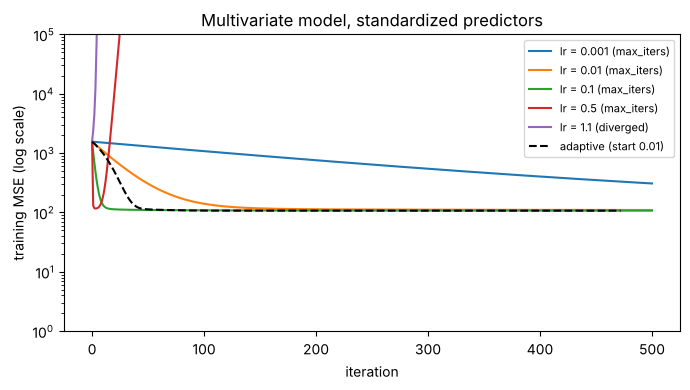

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.001, 0.01, 0.1, 0.5, 1.1]:
    _, info = gradient_descent(X_train_std, y_train, lr=lr, n_iters=500, tol=0)
    ax.plot(info["loss"], label=f"lr = {lr} ({info['status']})")
_, info = gradient_descent(X_train_std, y_train, lr=0.01, n_iters=500, tol=0, adaptive=True)
ax.plot(info["loss"], "k--", label="adaptive (start 0.01)")

ax.set_yscale("log"); ax.set_ylim(top=1e5)
ax.set_xlabel("iteration"); ax.set_ylabel("training MSE (log scale)")
ax.set_title("Multivariate model, standardized predictors")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**7. Univariate Models, one per predictor**

In [7]:
rows = []
for j, name in enumerate(features):
    theta, info = gradient_descent(X_train_std[:, j], y_train, lr=0.1)
    m_orig = theta[1] / scaler.scale_[j]
    b_orig = theta[0] - theta[1] * scaler.mean_[j] / scaler.scale_[j]
    rows.append({"feature": name, "m (std)": theta[1], "b (std)": theta[0],
                 "m (orig units)": m_orig, "b (orig units)": b_orig,
                 **evaluate(theta, X_train_std[:, j], y_train, X_test_std[:, j], y_test),
                 "iters": len(info["loss"]) - 1, "status": info["status"]})

uni_results = pd.DataFrame(rows).set_index("feature")
uni_results.round(4)

,m (std),b (std),m (orig units),b (orig units),train_MSE,train_R2,test_MSE,test_R2,iters,status
feature,,,,,,,,,,
cement,8.2337,35.822,0.0792,13.6250,210.1826,0.2439,206.5040,0.2744,67,converged
slag,2.2499,35.822,0.0262,33.8734,272.9145,0.0182,279.4748,0.0180,67,converged
fly_ash,-1.8958,35.822,-0.0296,37.4445,274.3825,0.0129,284.8924,-0.0011,67,converged
water,-4.9299,35.822,-0.2315,77.8646,253.6727,0.0874,267.6226,0.0596,67,converged
superplasticizer,6.2679,35.822,1.0532,29.1896,238.6896,0.1413,260.8465,0.0834,67,converged
coarse_agg,-2.5775,35.822,-0.0329,67.8456,271.3328,0.0239,270.7915,0.0485,67,converged
fine_agg,-2.6782,35.822,-0.0332,61.4561,270.8037,0.0258,272.6057,0.0421,67,converged
age,5.5297,35.822,0.0897,31.7747,247.3990,0.1100,257.6179,0.0948,67,converged


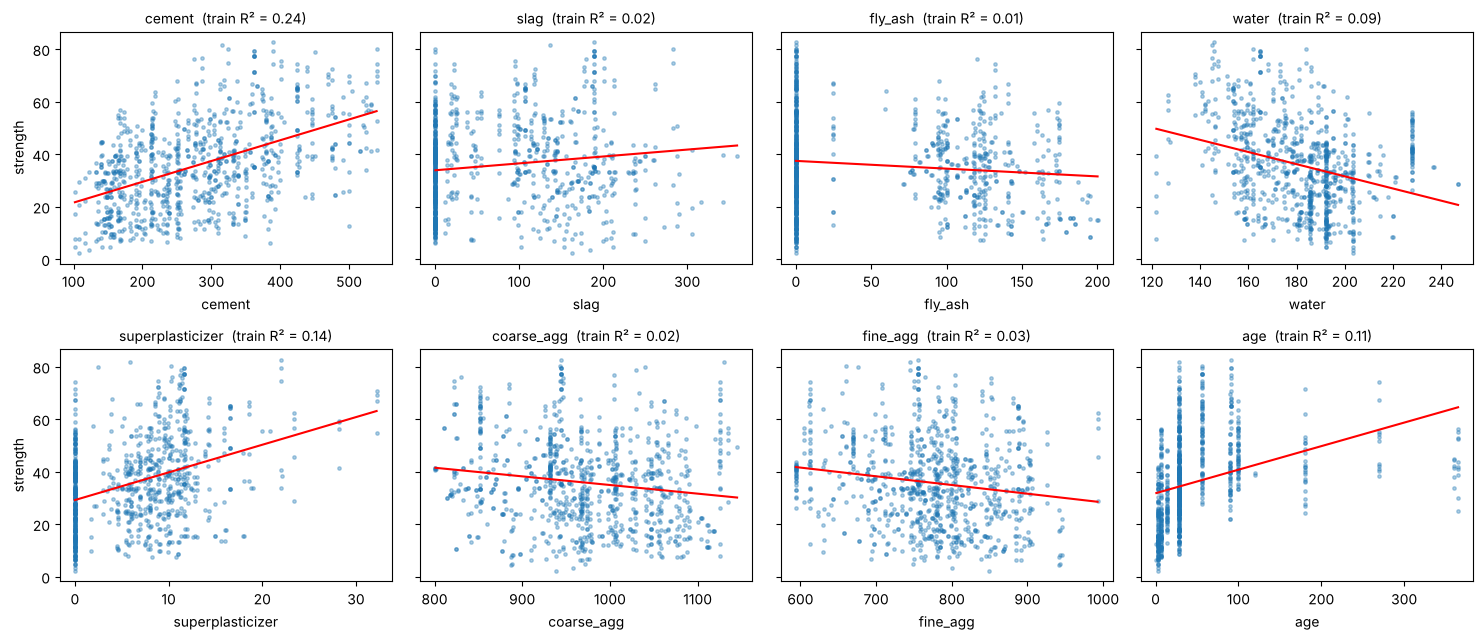

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharey=True)
for ax, (j, name) in zip(axes.ravel(), enumerate(features)):
    x = X_train_raw[:, j]
    ax.scatter(x, y_train, s=6, alpha=0.35)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, uni_results.loc[name, "m (orig units)"] * xs + uni_results.loc[name, "b (orig units)"], "r")
    ax.set_title(f"{name}  (train R² = {uni_results.loc[name, 'train_R2']:.2f})", fontsize=10)
    ax.set_xlabel(name)
axes[0, 0].set_ylabel("strength"); axes[1, 0].set_ylabel("strength")
plt.tight_layout(); plt.show()

**8. Multivariate model, all 8 predictors standardized**

In [9]:
theta_multi, info_multi = gradient_descent(X_train_std, y_train, lr=0.1, n_iters=50_000)
print(info_multi["status"], "after", len(info_multi["loss"]) - 1, "iterations")

display(pd.Series(theta_multi, index=["intercept"] + features, name="theta (std units)").round(4))
pd.Series(evaluate(theta_multi, X_train_std, y_train, X_test_std, y_test)).round(4)

converged after 1708 iterations


intercept           35.8220
cement              12.5881
slag                 9.0766
fly_ash              5.7486
water               -2.8054
superplasticizer     2.1076
coarse_agg           1.5624
fine_agg             1.7817
age                  7.1100
Name: theta (std units), dtype: float64

train_MSE    107.2488
train_R2       0.6142
test_MSE     107.4620
test_R2        0.6224
dtype: float64

**10. Raw (unscaled) predictors**

In [10]:
_, info = gradient_descent(X_train_raw, y_train, lr=0.01, n_iters=1000)
print("lr = 0.01 on raw data ->", info["status"], "after", len(info["loss"]) - 1, "iterations")

theta_raw_fixed, info_fixed = gradient_descent(X_train_raw, y_train, lr=1e-7, n_iters=100_000, tol=0)
theta_raw_adapt, info_adapt = gradient_descent(X_train_raw, y_train, lr=1e-7, n_iters=100_000, tol=0, adaptive=True)

raw_results = pd.DataFrame({
    "raw, fixed lr=1e-7":  evaluate(theta_raw_fixed, X_train_raw, y_train, X_test_raw, y_test),
    "raw, adaptive":       evaluate(theta_raw_adapt, X_train_raw, y_train, X_test_raw, y_test),
    "standardized":        evaluate(theta_multi, X_train_std, y_train, X_test_std, y_test),
}).T
raw_results.round(4)

lr = 0.01 on raw data -> diverged after 33 iterations


,train_MSE,train_R2,test_MSE,test_R2
"raw, fixed lr=1e-7",108.0283,0.6114,105.2538,0.6302
"raw, adaptive",107.4357,0.6135,106.4254,0.6260
standardized,107.2488,0.6142,107.4620,0.6224


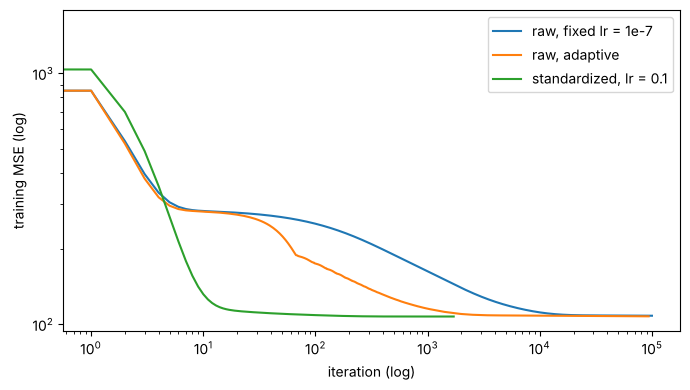

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(info_fixed["loss"], label="raw, fixed lr = 1e-7")
plt.plot(info_adapt["loss"], label="raw, adaptive")
plt.plot(info_multi["loss"], label="standardized, lr = 0.1")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("iteration (log)"); plt.ylabel("training MSE (log)")
plt.legend(); plt.tight_layout(); plt.show()

**11. Reference solution with scikit-learn**

In [12]:
sk_multi = LinearRegression().fit(X_train_raw, y_train)
theta_sk = np.r_[sk_multi.intercept_, sk_multi.coef_]

# Convert the standardized GD solution back to original units for a like-for-like comparison
m_orig = theta_multi[1:] / scaler.scale_
b_orig = theta_multi[0] - np.sum(theta_multi[1:] * scaler.mean_ / scaler.scale_)

display(pd.DataFrame({"sklearn": theta_sk,
                      "GD (std -> orig units)": np.r_[b_orig, m_orig],
                      "GD raw adaptive": theta_raw_adapt},
                     index=["intercept"] + features).round(4))

pd.concat([raw_results,
           pd.DataFrame({"sklearn LinearRegression":
                         evaluate(theta_sk, X_train_raw, y_train, X_test_raw, y_test)}).T]).round(4)

,sklearn,GD (std -> orig units),GD raw adaptive
intercept,-30.8763,-30.8690,-0.0004
cement,0.1211,0.1211,0.1140
slag,0.1058,0.1058,0.0976
fly_ash,0.0897,0.0897,0.0813
water,-0.1318,-0.1318,-0.1807
superplasticizer,0.3541,0.3541,0.2628
coarse_agg,0.0200,0.0200,0.0095
fine_agg,0.0221,0.0221,0.0115
age,0.1154,0.1154,0.1153


,train_MSE,train_R2,test_MSE,test_R2
"raw, fixed lr=1e-7",108.0283,0.6114,105.2538,0.6302
"raw, adaptive",107.4357,0.6135,106.4254,0.6260
standardized,107.2488,0.6142,107.4620,0.6224
sklearn LinearRegression,107.2488,0.6142,107.4621,0.6224


# **Data Analysis**

Use your implemented algorithm, a third-part linear model optimization tool (eg. scikit-learn.linear_model.LinearRegression), and a third-party statistical tool (e.g.,statsmodels.api.OLS) to explicitly answer the following questions.

,untransformed,standardized
learning rate used,2.99479e-07,0.219902
largest stable learning rate,5.98958e-07,0.439804
condition number,1.11841e+10,77.5539
iterations to R2 > 0,7,2
iterations to within 1% of optimal MSE,"10,248",56
iterations run,"200,000","200,000"
final train MSE,107.44,107.249
final train R2,0.613493,0.61418


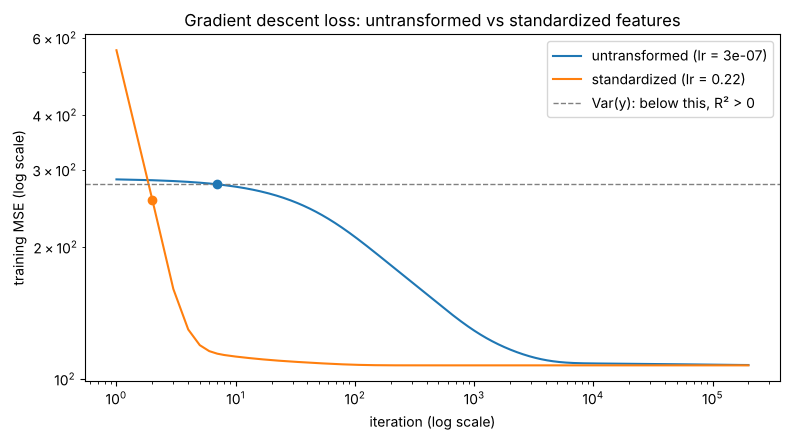

lr = 0.22 on untransformed features -> diverged after 25 iterations


In [13]:
import statsmodels.api as sm

def hessian_eigs(X):
    Xb = add_bias(X)
    return np.linalg.eigvalsh((2 / len(Xb)) * Xb.T @ Xb)      

def iters_to_positive_r2(loss_history, y):
    hit = np.where(loss_history < np.var(y))[0]
    return int(hit[0]) if len(hit) else None

def first_below(loss_history, level):
    hit = np.where(loss_history <= level)[0]
    return int(hit[0]) if len(hit) else None

best_mse = mse(y_train, LinearRegression().fit(X_train_raw, y_train).predict(X_train_raw))

runs = {}
for label, X in [("untransformed", X_train_raw), ("standardized", X_train_std)]:
    eig = hessian_eigs(X)
    lr = 1 / eig[-1]                       
    theta, info = gradient_descent(X, y_train, lr=lr, n_iters=200_000, tol=0)
    runs[label] = dict(theta=theta, loss=info["loss"], lr=lr,
                       cond=eig[-1] / eig[0], max_lr=2 / eig[-1],
                       hit=iters_to_positive_r2(info["loss"], y_train),
                       near=first_below(info["loss"], 1.01 * best_mse))

summary = pd.DataFrame({
    k: {"learning rate used": r["lr"],
        "largest stable learning rate": r["max_lr"],
        "condition number": r["cond"],
        "iterations to R2 > 0": r["hit"],
        "iterations to within 1% of optimal MSE": r["near"],
        "iterations run": len(r["loss"]) - 1,
        "final train MSE": r["loss"][-1],
        "final train R2": 1 - r["loss"][-1] / np.var(y_train)}
    for k, r in runs.items()})
pd.set_option("display.float_format", lambda v: f"{v:,.6g}")
display(summary)

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, r in runs.items():
    it = np.arange(len(r["loss"]))
    line, = ax.plot(it[1:], r["loss"][1:], label=f"{label} (lr = {r['lr']:.2g})")
    if r["hit"]:
        ax.scatter(r["hit"], r["loss"][r["hit"]], color=line.get_color(), zorder=3)
ax.axhline(np.var(y_train), color="gray", ls="--", lw=1, label="Var(y): below this, R² > 0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("iteration (log scale)"); ax.set_ylabel("training MSE (log scale)")
ax.set_title("Gradient descent loss: untransformed vs standardized features")
ax.legend(); plt.tight_layout(); plt.show()

_, bad = gradient_descent(X_train_raw, y_train, lr=runs["standardized"]["lr"], n_iters=1000)
print(f"lr = {runs['standardized']['lr']:.3g} on untransformed features -> "
      f"{bad['status']} after {len(bad['loss'])-1} iterations")

In [14]:
sk_raw = LinearRegression().fit(X_train_raw, y_train)
sk_std = LinearRegression().fit(X_train_std, y_train)

ols_raw = sm.OLS(y_train, sm.add_constant(X_train_raw)).fit()
ols_std = sm.OLS(y_train, sm.add_constant(X_train_std)).fit()

names = ["intercept"] + features
coef = pd.DataFrame({
    "raw coef":            np.r_[sk_raw.intercept_, sk_raw.coef_],
    "scaled coef":         np.r_[sk_std.intercept_, sk_std.coef_],
    "scaled -> raw units": np.r_[sk_std.intercept_ - np.sum(sk_std.coef_ * scaler.mean_ / scaler.scale_),
                                 sk_std.coef_ / scaler.scale_],
    "t (raw)": ols_raw.tvalues, "t (scaled)": ols_std.tvalues,
    "p (raw)": ols_raw.pvalues, "p (scaled)": ols_std.pvalues,
}, index=names)
display(coef)

fit = pd.DataFrame({
    "raw":    {"train MSE": mse(y_train, sk_raw.predict(X_train_raw)), "train R2": r2(y_train, sk_raw.predict(X_train_raw)),
               "test MSE":  mse(y_test,  sk_raw.predict(X_test_raw)),  "test R2":  r2(y_test,  sk_raw.predict(X_test_raw)),
               "statsmodels R2": ols_raw.rsquared},
    "scaled": {"train MSE": mse(y_train, sk_std.predict(X_train_std)), "train R2": r2(y_train, sk_std.predict(X_train_std)),
               "test MSE":  mse(y_test,  sk_std.predict(X_test_std)),  "test R2":  r2(y_test,  sk_std.predict(X_test_std)),
               "statsmodels R2": ols_std.rsquared}})
display(fit)

print("largest difference between raw-model and scaled-model predictions (test):",
      np.max(np.abs(sk_raw.predict(X_test_raw) - sk_std.predict(X_test_std))))
print("sklearn vs statsmodels, largest coefficient difference:",
      np.max(np.abs(np.r_[sk_raw.intercept_, sk_raw.coef_] - ols_raw.params)))

,raw coef,scaled coef,scaled -> raw units,t (raw),t (scaled),p (raw),p (scaled)
intercept,-30.8763,35.822,-30.8763,-1.08735,103.251,0.277177,0
cement,0.121075,12.5884,0.121075,12.9206,12.9206,3.96459e-35,3.96459e-35
slag,0.105836,9.07683,0.105836,9.63194,9.63194,5.8975e-21,5.8975e-21
fly_ash,0.0896711,5.74883,0.0896711,6.42166,6.42166,2.18994e-10,2.18994e-10
water,-0.131755,-2.80519,-0.131755,-3.07786,-3.07786,0.00214876,0.00214876
superplasticizer,0.354124,2.10759,0.354124,3.52266,3.52266,0.000448948,0.000448948
coarse_agg,0.0199578,1.56254,0.0199578,2.00545,2.00545,0.0452175,0.0452175
fine_agg,0.0220671,1.78195,0.0220671,1.92773,1.92773,0.0542067,0.0542067
age,0.11538,7.10999,0.11538,19.4759,19.4759,1.16559e-70,1.16559e-70


,raw,scaled
train MSE,107.249,107.249
train R2,0.61418,0.61418
test MSE,107.462,107.462
test R2,0.622392,0.622392
statsmodels R2,0.61418,0.61418


largest difference between raw-model and scaled-model predictions (test): 8.526512829121202e-14
sklearn vs statsmodels, largest coefficient difference: 1.4779288903810084e-12


**1. How does features scaling affect convergence speed and stability?**

**Response:** Scaling makes gradient descent far faster and far more stable. From the 'Gradient Descent Loss' plot, we can see that both models reach a positive R-squared almost immediately. The dashed line is Var(y), about 278. Standardized crosses it at iteration 2 and untransformed at about iteration 7 (the two dots). After that, the two behave very differently. Standardized is essentially at its floor (MSE about 108) within roughly 100 iterations. Untransformed needs on the order of 10,000 iterations to get to the same level, so it is about 100 times slower. Both flatten at an MSE of about 108, which is an R-squared of roughly 1 - 108/278 = 0.61. That supports the idea that scaling changes how fast you get there, not where you end up The learning rates differ by about six orders of magnitude (3e-7 against 0.22). That is the stability point that the raw features force a tiny step size.
Why standardizing fixes it is because every feature gets mean 0 and variance 1, so the Hessian becomes roughly the correlation matrix. Its eigenvalues are all near 1, the loss surface is close to round, and one learning rate suits every direction. Centering also makes the intercept independent of the slopes.

**2. Does a linear transformation meaningfully change the optimal solution?**

**Response:** No. The coefficients change, but the fitted model is the same. From the second cell of Data Analysis block, we can see that train and test MSE and R-squared are identical for the raw and scaled models, and their predictions differ only by floating-point error. Each scaled slope equals the raw slope times that feature's standard deviation, and the scaled intercept becomes the mean of y. The `scaled -> raw units` column converts back and matches the raw coefficients exactly. Statsmodels gives identical t-statistics and p-values for every slope. Only the intercept's t-statistic changes, because it now tests a different quantity (strength at average inputs rather than at all-zero inputs).

# **Part 1 (cont.): Non-Linear Transformations, Univariate vs. Multivariate, p-values**

These cells reuse the data split, `gradient_descent`, `add_bias`, `mse`, `r2`, and `scaler` defined above.

In [15]:
import statsmodels.api as sm

def hessian_eigs(X):
    Xb = add_bias(X)
    return np.linalg.eigvalsh((2 / len(Xb)) * Xb.T @ Xb)

def first_below(loss_history, level):
    hit = np.where(loss_history <= level)[0]
    return int(hit[0]) if len(hit) else None

def fit_metrics(model, Xtr, Xte):
    ptr, pte = model.predict(Xtr), model.predict(Xte)
    return {"Train MSE": mse(y_train, ptr), "Test MSE": mse(y_test, pte),
            "Train R2": r2(y_train, ptr), "Test R2": r2(y_test, pte)}

## **Q5. Non-Linear Transformations**

**Q5.1 Gradient descent on log(x+1) features: loss over iterations**

,learning rate (1/λmax),largest stable lr,condition number,iterations to R2 > 0,iterations to within 1% of optimal MSE,final GD train MSE,optimal train MSE
model,,,,,,,
untransformed,2.99479e-07,5.98958e-07,1.11841e+10,7,10248,107.44,107.249
standardized,0.219902,0.439804,77.5539,2,56,107.249,107.249
log(x+1),0.00285932,0.00571864,1.62635e+07,1,26547,54.5904,54.533


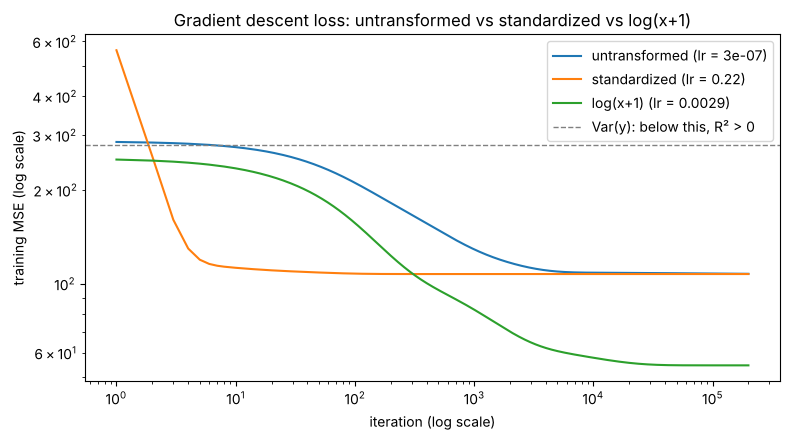

In [16]:
X_train_log = np.log1p(X_train_raw)
X_test_log  = np.log1p(X_test_raw)

sk_raw = LinearRegression().fit(X_train_raw, y_train)
sk_std = LinearRegression().fit(X_train_std, y_train)
sk_log = LinearRegression().fit(X_train_log, y_train)

runs_q5, rows = {}, []
for label, X, sk in [("untransformed", X_train_raw, sk_raw),
                     ("standardized",  X_train_std, sk_std),
                     ("log(x+1)",      X_train_log, sk_log)]:
    eig = hessian_eigs(X)
    lr = 1 / eig[-1]                                   # same learning-rate rule for every model
    theta, info = gradient_descent(X, y_train, lr=lr, n_iters=200_000, tol=0)
    opt = mse(y_train, sk.predict(X))
    runs_q5[label] = dict(theta=theta, loss=info["loss"], lr=lr)
    rows.append({"model": label, "learning rate (1/λmax)": lr, "largest stable lr": 2 / eig[-1],
                 "condition number": eig[-1] / eig[0],
                 "iterations to R2 > 0": first_below(info["loss"], np.var(y_train)),
                 "iterations to within 1% of optimal MSE": first_below(info["loss"], 1.01 * opt),
                 "final GD train MSE": info["loss"][-1], "optimal train MSE": opt})
display(pd.DataFrame(rows).set_index("model"))

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, r in runs_q5.items():
    ax.plot(np.arange(1, len(r["loss"])), r["loss"][1:], label=f"{label} (lr = {r['lr']:.2g})")
ax.axhline(np.var(y_train), color="gray", ls="--", lw=1, label="Var(y): below this, R² > 0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("iteration (log scale)"); ax.set_ylabel("training MSE (log scale)")
ax.set_title("Gradient descent loss: untransformed vs standardized vs log(x+1)")
ax.legend(); plt.tight_layout(); plt.savefig("q5_loss.png", dpi=150); plt.show()

**Q5.2 How does this non-linear feature transformation affect convergence speed and stability?**

**Response:** The log transform makes gradient descent much more stable, but only partly faster. It shrinks large values (around 1000) to small values (around 7). It lets us use a learning rate about 10,000 times larger without the loss blowing up, but it still takes too long to fully converge. The average log feature is not 0; it still needs about 26000 iterations to get close to the best answer, while standardized features need only about 56.

**Q5.3 Optimal solution for the log-transformed model (scikit-learn), and summary table**

In [17]:
display(pd.Series(np.r_[sk_log.intercept_, sk_log.coef_], index=["intercept"] + features,
                  name="log-model coefficient").round(4))

summary_q5 = pd.DataFrame({"Untransformed":   fit_metrics(sk_raw, X_train_raw, X_test_raw),
                           "Standardized":    fit_metrics(sk_std, X_train_std, X_test_std),
                           "Log-Transformed": fit_metrics(sk_log, X_train_log, X_test_log)}).T
summary_q5.round(4)

intercept           72.7396
cement              23.8028
slag                 2.2634
fly_ash              0.2062
water              -34.7884
superplasticizer     2.6804
coarse_agg           3.0576
fine_agg            -7.3181
age                  8.8889
Name: log-model coefficient, dtype: float64

,Train MSE,Test MSE,Train R2,Test R2
Untransformed,107.249,107.462,0.6142,0.6224
Standardized,107.249,107.462,0.6142,0.6224
Log-Transformed,54.533,58.3224,0.8038,0.7951


**Q5.4 How does a non-linear transformation differ from a linear one in its impact on the optimal solution and predictive performance?**

**Response:** A linear transformation like standardization doesn't change the model; it only rescales the coefficients, so the predictions, MSE, and R^2 remain unchanged. A non-linear transformation changes the model so it can fit curved patterns. For example, the strength rises quickly at early ages and then levels off. As a result, the log model fits much better than the standardization model.

## **Q6. Univariate vs. Multivariate Coefficients**

**Q6.1 Gradient descent on 8 univariate models (untransformed predictors)**

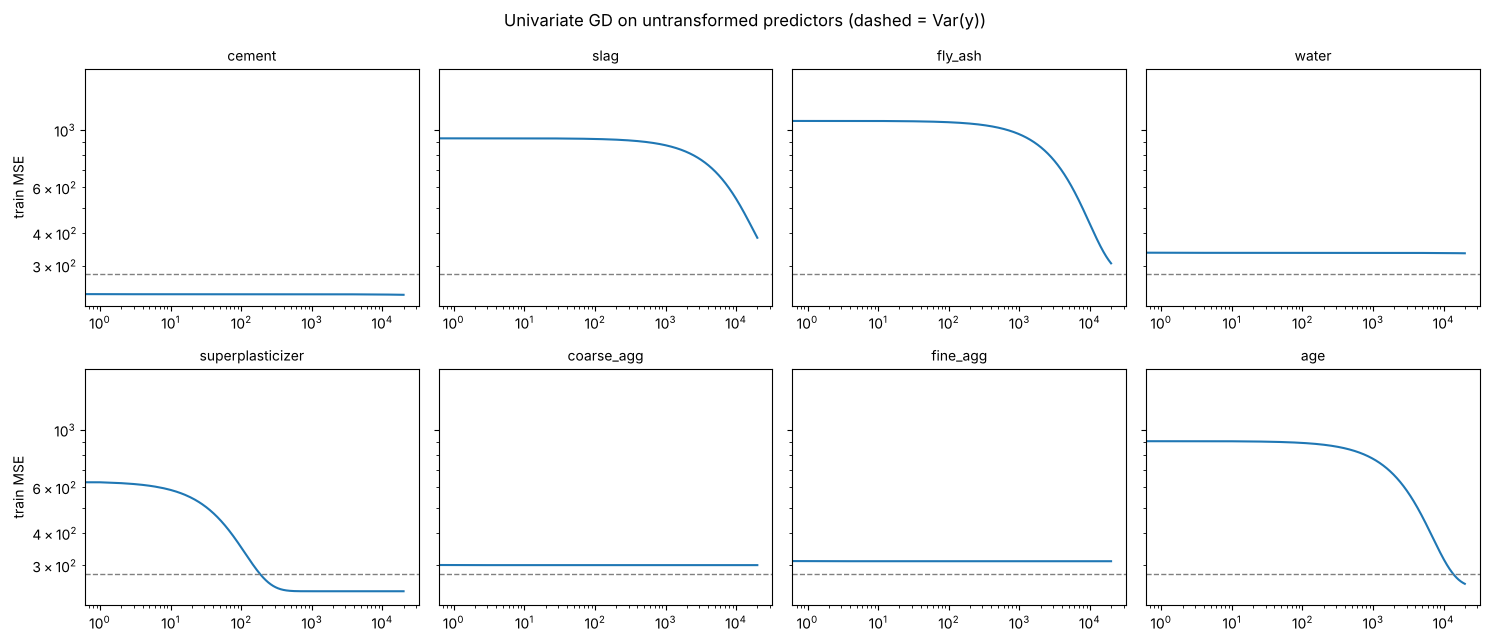

,learning rate,iterations to R2 > 0,GD train R2 (20k iters),GD slope,GD intercept
feature,,,,,
cement,5.59432e-06,1,0.167368,0.12078,0.364195
slag,3.8841e-05,NaN,-0.381313,0.106684,19.932
fly_ash,7.02146e-05,NaN,-0.100826,0.0274666,30.043
water,1.496e-05,NaN,-0.203624,0.188048,0.630425
superplasticizer,0.00661259,186,0.141332,1.05316,29.1896
coarse_agg,5.25044e-07,NaN,-0.0826566,0.0363685,0.00920803
fine_agg,8.2795e-07,NaN,-0.120801,0.0454606,0.0220311
age,8.57341e-05,"13,739",0.0828256,0.116081,28.3687


In [18]:
uni_rows = []
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharey=True)
for ax, (j, name) in zip(axes.ravel(), enumerate(features)):
    x = X_train_raw[:, j]
    lr = 1 / hessian_eigs(x)[-1]
    theta, info = gradient_descent(x, y_train, lr=lr, n_iters=20_000, tol=0)
    uni_rows.append({"feature": name, "learning rate": lr,
                     "iterations to R2 > 0": first_below(info["loss"], np.var(y_train)),
                     "GD train R2 (20k iters)": r2(y_train, add_bias(x) @ theta),
                     "GD slope": theta[1], "GD intercept": theta[0]})
    ax.plot(info["loss"]); ax.axhline(np.var(y_train), color="gray", ls="--", lw=1)
    ax.set_yscale("log"); ax.set_xscale("log"); ax.set_title(name, fontsize=10)
axes[0, 0].set_ylabel("train MSE"); axes[1, 0].set_ylabel("train MSE")
plt.suptitle("Univariate GD on untransformed predictors (dashed = Var(y))"); plt.tight_layout(); plt.show()

uni_gd = pd.DataFrame(uni_rows).set_index("feature")
uni_gd

**Which models were easy to train? Which were hard?**

**Response:** Easy: superplasticizer, cement, and age showed positive R^2 values.  
Hard: slag, fly ash, water, coarse aggregate, fine aggregate.  
These resulted in negative R^2 values even after 20000 iterations.

**Q6.2 Optimal univariate coefficients (scikit-learn) vs. the optimal untransformed multivariate model**

In [19]:
coef_cmp = pd.DataFrame({
    "univariate slope": [LinearRegression().fit(X_train_raw[:, [j]], y_train).coef_[0] for j in range(len(features))],
    "univariate R2":    [LinearRegression().fit(X_train_raw[:, [j]], y_train).score(X_train_raw[:, [j]], y_train) for j in range(len(features))],
    "multivariate weight": sk_raw.coef_}, index=features)
coef_cmp["sign flips"] = np.sign(coef_cmp["univariate slope"]) != np.sign(coef_cmp["multivariate weight"])
display(coef_cmp.round(4))

pd.DataFrame(X_train_raw, columns=features).assign(strength=y_train).corr().round(2)

,univariate slope,univariate R2,multivariate weight,sign flips
cement,0.0792,0.2439,0.1211,False
slag,0.0262,0.0182,0.1058,False
fly_ash,-0.0296,0.0129,0.0897,True
water,-0.2315,0.0874,-0.1318,False
superplasticizer,1.0532,0.1413,0.3541,False
coarse_agg,-0.0329,0.0239,0.02,True
fine_agg,-0.0332,0.0258,0.0221,True
age,0.0897,0.11,0.1154,False


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
cement,1,-0.27,-0.42,-0.07,0.08,-0.09,-0.24,0.1,0.49
slag,-0.27,1,-0.33,0.1,0.04,-0.28,-0.26,-0.07,0.13
fly_ash,-0.42,-0.33,1,-0.26,0.38,-0.01,0.08,-0.15,-0.11
water,-0.07,0.1,-0.26,1,-0.66,-0.18,-0.45,0.26,-0.3
superplasticizer,0.08,0.04,0.38,-0.66,1,-0.27,0.23,-0.18,0.38
coarse_agg,-0.09,-0.28,-0.01,-0.18,-0.27,1,-0.2,0.01,-0.15
fine_agg,-0.24,-0.26,0.08,-0.45,0.23,-0.2,1,-0.14,-0.16
age,0.1,-0.07,-0.15,0.26,-0.18,0.01,-0.14,1,0.33
strength,0.49,0.13,-0.11,-0.3,0.38,-0.15,-0.16,0.33,1


**Are they identical?**

**Response:** Not identical. Every univariate coefficient is different from its multivariate weight. Furthermore, fly ash, coarse aggregate, and fine aggregate have negative univariate slopes but positive multivariate weights.

**Why are univariate coefficients not equal to multivariate coefficients?**

**Response:** It is because many of the ingredients are correlated. A univariate model considers only one ingredient, so it also picks up the effect of the ingredients it leaves out --this phenomenon is called omitted variable bias.

For example, mixes with more fly ash usually have less cement, and cement makes concrete stronger. So fly ash alone looks bad, but with cement in the model, fly ash actually helps.

## **Q7. Statistical Significance (p-values)**

In [20]:
ols_raw = sm.OLS(y_train, sm.add_constant(X_train_raw)).fit()
ols_std = sm.OLS(y_train, sm.add_constant(X_train_std)).fit()
ols_log = sm.OLS(y_train, sm.add_constant(X_train_log)).fit()

pvals = pd.DataFrame({"Untransformed": ols_raw.pvalues,
                      "Standardized": ols_std.pvalues,
                      "Log-Transformed": ols_log.pvalues}, index=["intercept"] + features)
pvals.map(lambda v: f"{v:.3g}")

,Untransformed,Standardized,Log-Transformed
intercept,0.277,0,0.333
cement,3.96e-35,3.96e-35,5.84e-88
slag,5.9e-21,5.9e-21,3.19e-36
fly_ash,2.19e-10,2.19e-10,0.259
water,0.00215,0.00215,3.47e-17
superplasticizer,0.000449,0.000449,1.2e-10
coarse_agg,0.0452,0.0452,0.53
fine_agg,0.0542,0.0542,0.0623
age,1.17e-70,1.17e-70,1.1e-194


**Are there any trends between which predictors are important and which univariate models were easy or hard to train?**

**Response:** Cement and age are easy to train and among the most significant predictors, whereas coarse/fine aggregates are hard to train and the least significant.  
Slag was hard to train but still highly significant. So training difficulty is not related to how important the feature is.

**Which transformation type drastically changes significance, and which does not? Why?**

**Response:** Standardization does not change any feature's p-value. It only rescales numbers, but the model still stays. Only the intercept's p-value changes.  
The log transform changes the p-value a lot because it changes the model. Fly ash and coarse aggregate become not significant, while other elements become more significant.  
In short, the log model fits the data better, so the important effects stand out more clearly and the weak ones fade away.